# Path dependency and Monte Carlo simulations
Options with payoffs that depend on the path taken by the underlying and not only on the value at expiration are said to be path-dependent. In this notebook, we will analyze Monte Carlo Simulation of these options. 

- Options analyzed in this notebook do not have closed-form solutions
  
- We classify options as weakly or strongly path dependent
 
- Path dependency is manifest as an extra variable in the option pricing besides $t$ and $S_t$ characterizing the path

We model American options following the classic paper by Longstaff-Schwartz  "_Valuing American Options by Simulation: A Simple Least-Squares Approach_", Review of Financial Studies 14(1), 113-147.  We will consider only non-dividend paying options.


In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd

from vanilla_options import bs_put
from path_dependent_options import american_put_LSM
from geometric_brownian_motion import generate_GBM_paths
from numerical_PDEs import american_put_fdm


## Weak path dependency: American put

American options incorporate early exercise and path dependence but we can still characterize the price by $S_t$ and $t$. However early excercise makes the American options an optimization problem. Despite its dependence on the path American options with a European-like payoff are weakly path dependent, that is we do not require an additional variable to describe its price.   Let $V(S, t)$ denote the price of an option with a vanilla-like payoff. For concreteness, let us consider a European put with payoff
$$
G(S, t)= \text{max}(E-S) \, ,
$$
where $E$ is the strike price and $S$ is the stock price. The price of the option at present time ($t=0$) is defined as 
$$
V_0 = \sup_{t \in \mathcal{T}_{[0,T]}} \mathbb{E}^{\mathbb {Q}}\!\left[
  e^{-rt} G(S_t, t) \right],
$$
where $\mathbb {Q}$ is a risk-neutral measure, $r$ is the risk-free rate, and $\mathcal{T}_{[0,T]}$ is the set of stopping times with values in $[0,T]$. The optimal stopping time solves this supremum. In practice, we discretize $[0,T]$ to a grid $0=t_0, t_1, \dots, t_N=N$ and search over stopping times taking values in this grid.

The Monte-Carlo simulation of this option follows the Longstaff--Schwartz least squares method (LSM). The method can be summarized as follows.

- Simulate $M$ paths forward from $S_0$ to $T$ on a grid of $N+1$
  dates; record the matrix $S_{m,n}$ of all simulated prices.
  
- Starting at $T$ and moving backward in time, at each date
  $t_n$ with $0 < n < N$: identify the paths that are in-the-money
  (ITM) at $t_n$; regress the (already-computed, discounted)
  continuation values on a set of basis functions of $S_{t_n}$; this
  regression gives an approximation
  $\hat C_n(S) = \sum_k \beta_k \psi_k(S)$ of the continuation value
  $C_n(S) = \mathbb{E}^{\mathbb{Q}}[V_{n+1} \mid S_{t_n} = S]$.

  
 - At each ITM path, compare the immediate exercise payoff
  $G(t_n, S_{m,n})$ with the regression-estimated continuation value
  $\hat C_n(S_{m,n})$. If the exercise payoff exceeds the continuation
  value, mark the path as "exercise at $t_n$" and update its value to
  the exercise payoff; otherwise the path carries forward its existing
  (discounted) future value.

After the backward sweep, the time-0 price is the average of the path-wise discounted values. The choice of basis functions is important
but not critical. We will use a power-like regression approach and use ${1, S, S^2, \dots }$ as our basis. 


### Create data framework to reproduce table 1 in Section 3 of LSM paper
Table 1 has the values $r=0.06$ and strike $K=40$. The calculation assumes that the option can be exercised 50 times per year and uses $100\ 000$ paths using antithetic variates. 

In [2]:
rate, strike_price, n_times_exercise, m_paths =0.06, 40, 50,  50_000

In [3]:
#Values explored in table 1 page 127 of ppublished paper
cases = [(S, sig, T) for S in [36, 38, 40, 42, 44] for sig in [0.20, 0.40] for T in [1.0, 2.0]]

In [4]:
#date frame which we fill with our calculations
df = pd.DataFrame({
    'S':     [c[0] for c in cases],
    'sigma': [c[1] for c in cases],
    'T':     [c[2] for c in cases],
    'European':        np.nan,
    'American (FDM)':  np.nan,
    'American (LSM)':  np.nan,
    '(s.e.)':          np.nan,
    'Early Ex. (FDM)': np.nan,
    'Early Ex. (LSM)': np.nan,
    'Diff in Ex. value': np.nan,
})
df

,S,sigma,T,European,American (FDM),American (LSM),(s.e.),Early Ex. (FDM),Early Ex. (LSM),Diff in Ex. value
0,36,0.2,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,36,0.2,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,36,0.4,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,36,0.4,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,38,0.2,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,38,0.2,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,38,0.4,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,38,0.4,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,40,0.2,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,40,0.2,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Let us first compute the European puts
for i, row in df.iterrows():
    S_table,  sigma_table, t_ex_table = row['S'], row['sigma'], row['T']
    df.at[i, 'European']=bs_put(S_table, strike_price, rate, sigma_table,  t_ex_table)

In [6]:
#Now compute the American options numerically
for i, row in df.iterrows():
    S_table,  sigma_table, t_ex_table = row['S'], row['sigma'], row['T']
    price, _ = american_put_fdm(S0=S_table, K=strike_price, r=rate, sigma=sigma_table,  T=t_ex_table, Nx=500, Nt=5000, x_range=2.0)
    df.at[i, 'American (FDM)']= price

In [7]:
#Now compute the American options by LSM
for i, row in df.iterrows():
    S_table,  sigma_table, t_ex_table = row['S'], row['sigma'], row['T']
    n_step_table=int(t_ex_table * n_times_exercise)
    price, error = american_put_LSM(S0=S_table, strike_price=strike_price, rate=rate, volatility=sigma_table,  t_exercise=t_ex_table,
                                m_paths=m_paths, n_steps=n_step_table, seed= 1298774398, deg=3)
    df.at[i, 'American (LSM)']= price
    df.at[i, '(s.e.)']= error
    

In [8]:
#Compute the differences
df['Early Ex. (FDM)'] = df['American (FDM)'] - df['European']
df['Early Ex. (LSM)'] = df['American (LSM)'] - df['European']
df['Diff in Ex. value'] =df['Early Ex. (FDM)'] - df['Early Ex. (LSM)']

In [9]:
df.round(3)

,S,sigma,T,European,American (FDM),American (LSM),(s.e.),Early Ex. (FDM),Early Ex. (LSM),Diff in Ex. value
0,36,0.2,1.0,3.844,4.479,4.477,0.008,0.635,0.633,0.002
1,36,0.2,2.0,3.763,4.837,4.837,0.010,1.074,1.074,0.001
2,36,0.4,1.0,6.711,7.107,7.084,0.012,0.396,0.372,0.023
3,36,0.4,2.0,7.700,8.512,8.474,0.015,0.812,0.774,0.039
4,38,0.2,1.0,2.852,3.247,3.240,0.007,0.395,0.388,0.007
5,38,0.2,2.0,2.991,3.739,3.732,0.009,0.748,0.741,0.007
6,38,0.4,1.0,5.834,6.153,6.143,0.011,0.318,0.309,0.009
7,38,0.4,2.0,6.979,7.673,7.652,0.014,0.694,0.673,0.021
8,40,0.2,1.0,2.066,2.309,2.312,0.007,0.242,0.245,-0.003
9,40,0.2,2.0,2.356,2.876,2.888,0.009,0.521,0.532,-0.012


## Strong path dependency 

### Americanized Arithmetic Asian put option
The payoff of this options reads

$$
V(\{S_t\})= \max(E-A_{t_n}, 0), \quad  A_{t_n}= \frac {1}{n+1} \sum_{k=0}^n S_{t_k} \, ,
$$
exercisable at any $t_n\in \set{t_1, t_2, \dots, t_N}$. Unlike the American put, here we need an additional variable to characterize the option. In this sense, the option is strongly path-dependent. 


In [10]:
from path_dependent_options import arithmethic_asian, americanized_asian
from geometric_brownian_motion import generate_GBM_paths
from numerical_PDEs import american_asian_put_fdm, asian_put_dp_err

In [11]:
rate, strike_price, n_times_exercise, m_paths =0.06, 40, 50,  50_000
cases = [(S, sig, T) for S in [36, 38, 40, 42, 44] for sig in [0.20, 0.40] for T in [1.0, 2.0]]

In [12]:
#date frame which we fill with our calculations for strong path dependent option
data_frame_strong = pd.DataFrame({
    'S':     [c[0] for c in cases],
    'sigma': [c[1] for c in cases],
    'T':     [c[2] for c in cases],
    'European':        np.nan,
    'American Asian (FDM)':  np.nan,
    '(err num)':          np.nan,   
    'American Asian (LSM)':  np.nan,
    '(s.e.)':          np.nan,
    
#    'Early Ex. (FDM)': np.nan,
#    'Early Ex. (LSM)': np.nan,
#    'Diff in Ex. value': np.nan,
})


In [13]:
# Let us first add our european puts
for i, row in data_frame_strong.iterrows():
    S_table,  sigma_table, t_ex_table = row['S'], row['sigma'], row['T']
    data_frame_strong.at[i, 'European']=bs_put(S_table, strike_price, rate, sigma_table,  t_ex_table)

In [14]:
#this takes a while
for i, row in data_frame_strong.iterrows():
    S_table,  sigma_table, t_ex_table = row['S'], row['sigma'], row['T']
    price, error, _= asian_put_dp_err(S0=S_table, K=strike_price, r=rate, sigma=sigma_table,  T=t_ex_table, n_per_year=50,
                                      pts_per_std=2.5, nA=200)
    data_frame_strong.at[i, 'American Asian (FDM)']= price
    data_frame_strong.at[i, '(err num)']= error    

In [15]:
for i, row in data_frame_strong.iterrows():
    S_table,  sigma_table, t_ex_table = row['S'], row['sigma'], row['T']
    n_step_table=int(t_ex_table * n_times_exercise)
    price, error= americanized_asian(S0=S_table, strike_price=strike_price, rate=rate, volatility=sigma_table,  t_exercise=t_ex_table, m_paths=m_paths,
                                      n_steps= n_step_table, deg=3)
    data_frame_strong.at[i, 'American Asian (LSM)']= price
    data_frame_strong.at[i, '(s.e.)']= error

In [16]:
data_frame_strong

,S,sigma,T,European,American Asian (FDM),(err num),American Asian (LSM),(s.e.)
0,36,0.2,1.0,3.844308,4.604420,0.000326,4.654784,0.005790
1,36,0.2,2.0,3.763001,4.748382,0.001163,4.779237,0.007092
2,36,0.4,1.0,6.711399,5.992483,0.000775,5.917260,0.009730
3,36,0.4,2.0,7.700040,6.717639,0.002661,6.644922,0.011689
4,38,0.2,1.0,2.851932,2.838498,0.000430,2.803096,0.006014
5,38,0.2,2.0,2.990557,3.095865,0.001462,3.055346,0.007536
6,38,0.4,1.0,5.834321,4.605877,0.000814,4.508896,0.010228
7,38,0.4,2.0,6.978802,5.481900,0.002955,5.400598,0.012238
8,40,0.2,1.0,2.066401,1.546320,0.000438,1.498753,0.006425
9,40,0.2,2.0,2.355866,1.902740,0.001613,1.861399,0.007947


### Analysis

Early exercise generally speaking add value to the option. Therefore American options are usually more expensive than Vanilla options. On the other hand Asian option takes the average of the underlying over some prescribed period and this decreases its price when compared against a similar Vanilla. Thus, we have the inequalities
$$
V^{\text{Vanilla}} \le V^{\text{American}}, \qquad   V^{\text{Asian}} \le V^{\text{Vanilla}}
$$

The americanization of the Asian option would  suggest that a similar inequality holds for the americanized asian option. However, this is not always the case. In order to see this, let us compare them. I will use the MC values. 

In [17]:
data_frame_comparison = pd.DataFrame({
    'S':     [c[0] for c in cases],
    'sigma': [c[1] for c in cases],
    'T':     [c[2] for c in cases],
    'American Asian (LSM)':        np.nan, 
    'European':        np.nan,
    'American (LSM)':  np.nan,
#   '(s.e.)':          np.nan,
    
#    'Early Ex. (FDM)': np.nan,
#    'Early Ex.': np.nan,
    'American-(American Asian)': np.nan,
    'European-(American Asian)': np.nan,
})


In [18]:
data_frame_comparison['American Asian (LSM)']=data_frame_strong['American Asian (LSM)']
data_frame_comparison['European']=data_frame_strong['European']
data_frame_comparison['American (LSM)']=df['American (LSM)']
data_frame_comparison['American-(American Asian)']=data_frame_comparison['American (LSM)']-data_frame_comparison['American Asian (LSM)']
data_frame_comparison['European-(American Asian)']=data_frame_comparison['European']-data_frame_comparison['American Asian (LSM)']


In [19]:
data_frame_comparison.round(3)

,S,sigma,T,American Asian (LSM),European,American (LSM),American-(American Asian),European-(American Asian)
0,36,0.2,1.0,4.655,3.844,4.477,-0.178,-0.810
1,36,0.2,2.0,4.779,3.763,4.837,0.058,-1.016
2,36,0.4,1.0,5.917,6.711,7.084,1.166,0.794
3,36,0.4,2.0,6.645,7.700,8.474,1.829,1.055
4,38,0.2,1.0,2.803,2.852,3.240,0.437,0.049
5,38,0.2,2.0,3.055,2.991,3.732,0.676,-0.065
6,38,0.4,1.0,4.509,5.834,6.143,1.635,1.325
7,38,0.4,2.0,5.401,6.979,7.652,2.252,1.578
8,40,0.2,1.0,1.499,2.066,2.312,0.813,0.568
9,40,0.2,2.0,1.861,2.356,2.888,1.027,0.494


The expected behavior is violated in a few cases of low volatility and longer exercise time. This is consistent with the conclusion of G.L. Ye in the article "_Asian options versus vanilla options: a boundary analysis._" Journal of Risk
Finance, 9(2):188–195, 2008.

In [55]:
sigmas_test=np.linspace(0.05, 0.5, 20)

In [56]:
S0_test, strike_price_test, t_test, n_steps_test= 36,  40, 1, 50 

In [57]:
check_vals_Am_Asian=[americanized_asian(S0=S0_test, strike_price=strike_price_test, rate=rate, volatility=sigmas,  t_exercise=t_test, m_paths=m_paths,
                                      n_steps= n_steps_test, deg=3)[0] for sigmas in sigmas_test]

In [58]:
check_vals_Am=[american_put_LSM(S0=S0_test, strike_price=strike_price_test, rate=rate, volatility=sigmas,  t_exercise=t_test, m_paths=m_paths,
                                      n_steps= n_steps_test, deg=3)[0] for sigmas in sigmas_test]


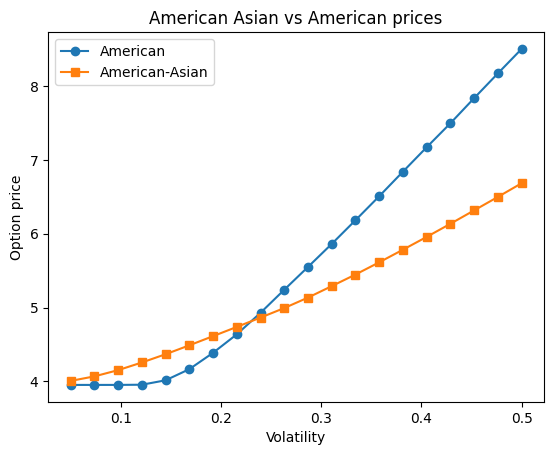

In [69]:
import matplotlib.pyplot as plt
plt.plot(sigmas_test, check_vals_Am,   marker="o" , label='American')
plt.plot(sigmas_test, check_vals_Am_Asian,   marker="s", label='American-Asian')
plt.xlabel("Volatility" )
plt.ylabel("Option price" )
plt.title("American Asian vs American prices")
plt.legend()
plt.savefig('american_asian_comparison.png', dpi=300, transparent=True, bbox_inches='tight')

plt.show()